# Heat flow through a wall with a thermal bridge: linear temperatures against Raviart–Thomas fluxes

Companion notebook to *Variational Methods in Computational Mechanics* (S. Vidoli),
Chapter 8, Section "Heat Flow Through a Wall with a Thermal Bridge", Example "An Insert Through the Insulation".

A wall of insulation (conductivity $k$, thickness 1) is crossed from its inner face by conducting inserts
(conductivity $k_b$), repeated with period 1. The inner face is at $\theta = 1$, the outer one at $\theta = 0$,
and by symmetry we compute on the half cell $\Omega = (0,1)\times(0,\tfrac12)$, with the insert
$(0, x_b)\times(0, y_b)$ and no heat flow across $y = 0$ and $y = \tfrac12$.

* **Primal**: the temperature minimizes $\mathcal E(\theta) = \tfrac12\int_\Omega k|\nabla\theta|^2$; linear triangles ($P_1$).
* **Mixed**: the flux $\mathbf q$ and the temperature solve
  $\int \mathbf q\cdot\mathbf r/k - \int\theta\,\mathrm{div}\,\mathbf r = -\int_{x=0}\mathbf r\cdot\mathbf n$,
  $\int s\,\mathrm{div}\,\mathbf q = 0$; Raviart–Thomas fluxes (one unknown per edge) and constant temperatures.

The heat flow $Q$ (per unit depth) is bracketed: $Q_{RT} \le Q \le Q_{P_1}$.

**How to use it.** Run the cells in order (*Runtime → Run all* in Colab). Then change the parameters in the next
cell and run everything again.

In [1]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

# ---------------------------------------------------------------- PARAMETERS
k_ins, k_b = 1.0, 100.0     # conductivity of the insulation and of the insert
xb, yb     = 0.6, 0.1       # the insert occupies (0, xb) x (0, yb)
H          = 0.5            # height of the half cell
n_plot     = 40             # elements per unit length, for the plots
n_conv     = [10, 20, 40, 80]  # meshes of the convergence study

## Mesh and the two solvers
Structured mesh: squares cut by a diagonal, with nodes on the faces of the insert.

In [2]:
def make_mesh(n):
    xs = np.unique(np.r_[np.linspace(0, xb, max(1, round(n*xb)) + 1), np.linspace(xb, 1, max(1, round(n*(1 - xb))) + 1)])
    ys = np.unique(np.r_[np.linspace(0, yb, max(2, round(n*yb)) + 1), np.linspace(yb, H, max(1, round(n*(H - yb))) + 1)])
    X, Y = np.meshgrid(xs, ys, indexing='ij'); P = np.c_[X.ravel(), Y.ravel()]
    ny = len(ys); T = []
    for i in range(len(xs) - 1):
        for j in range(ny - 1):
            a, b, c, d = i*ny + j, (i + 1)*ny + j, (i + 1)*ny + j + 1, i*ny + j + 1
            T += [[a, b, c], [a, c, d]]
    T = np.array(T); cen = P[T].mean(1)
    k = np.where((cen[:, 0] < xb) & (cen[:, 1] < yb), k_b, k_ins)
    return P, T, k

def solve_p1(P, T, k):
    """Linear triangles: temperature at the nodes, flux -k grad(theta) constant on each triangle."""
    I, J, V, G = [], [], [], []
    for t, tri in enumerate(T):
        X = P[tri]; Jm = (X[1:] - X[0]).T; A = abs(np.linalg.det(Jm))/2
        g = np.linalg.solve(Jm.T, np.array([[-1., 1, 0], [-1, 0, 1]])); G.append(g)
        Ke = k[t]*A*g.T @ g
        for a in range(3):
            for b in range(3): I.append(tri[a]); J.append(tri[b]); V.append(Ke[a, b])
    K = sp.csr_matrix((V, (I, J)), shape=(len(P), len(P)))
    th = np.zeros(len(P)); left = np.isclose(P[:, 0], 0); fixed = left | np.isclose(P[:, 0], 1)
    th[left] = 1; free = ~fixed
    th[free] = spla.spsolve(K[free][:, free].tocsc(), -K[free][:, fixed] @ th[fixed])
    q = np.array([-k[t]*G[t] @ th[T[t]] for t in range(len(T))])
    return th, th @ (K @ th), q          # Q_P1 = int k |grad theta_h|^2

def solve_rt(P, T, k):
    """Raviart-Thomas fluxes (one unknown per edge, the flux through it) and constant temperatures."""
    E, TE = {}, np.zeros((len(T), 3), int)
    for t, tri in enumerate(T):
        for a in range(3):                      # edge a is opposite to vertex a
            e = tuple(sorted((tri[(a + 1) % 3], tri[(a + 2) % 3]))); TE[t, a] = E.setdefault(e, len(E))
    ed = np.array(sorted(E, key=E.get)); ne = len(ed); mid = P[ed].mean(1)
    tg = P[ed[:, 1]] - P[ed[:, 0]]; L = np.linalg.norm(tg, axis=1); nrm = np.c_[tg[:, 1], -tg[:, 0]]/L[:, None]
    bnd = np.bincount(TE.ravel(), minlength=ne) == 1
    SG = np.zeros((len(T), 3)); I, J, V, Bi, Bj, Bv = [], [], [], [], [], []
    for t, tri in enumerate(T):
        X = P[tri]; A = abs(np.linalg.det((X[1:] - X[0]).T))/2; c = X.mean(0)
        for a in range(3):
            e = TE[t, a]
            if bnd[e] and np.dot(nrm[e], mid[e] - c) < 0: nrm[e] *= -1   # outer normal on the boundary
            SG[t, a] = 1. if np.dot(nrm[e], mid[e] - c) > 0 else -1.      # does the edge flux leave T?
        mp = [(X[(a + 1) % 3] + X[(a + 2) % 3])/2 for a in range(3)]      # edge midpoints: exact for quadratics
        N = lambda a, x: SG[t, a]*(x - X[a])/(2*A)
        for a in range(3):
            for b in range(3):
                I.append(TE[t, a]); J.append(TE[t, b]); V.append(A/3*sum(N(a, x) @ N(b, x) for x in mp)/k[t])
            Bi.append(t); Bj.append(TE[t, a]); Bv.append(SG[t, a])      # int_T div N = +-1
    Am = sp.csr_matrix((V, (I, J)), shape=(ne, ne)); B = sp.csr_matrix((Bv, (Bi, Bj)), shape=(len(T), ne))
    left = bnd & np.isclose(mid[:, 0], 0); right = bnd & np.isclose(mid[:, 0], 1)
    keep = np.where(~(bnd & ~left & ~right))[0]                         # drop the edges on the symmetry lines
    F = np.zeros(ne); F[left] = -1.0                                     # -int_{x=0} theta N.n, theta = 1
    S = sp.bmat([[Am[keep][:, keep], -B[:, keep].T], [-B[:, keep], None]]).tocsc()
    sol = spla.spsolve(S, np.r_[F[keep], np.zeros(len(T))])
    q = np.zeros(ne); q[keep] = sol[:len(keep)]
    return dict(q=q, theta=sol[len(keep):], Q=-q[left].sum(), Qout=q[right].sum(), TE=TE, SG=SG,
                edges=ed, nrm=nrm, mid=mid, L=L, div=np.abs(B @ q).max())

def rt_value(P, T, r, t, x):
    """The Raviart-Thomas flux of triangle t at the point x."""
    X = P[T[t]]; A = abs(np.linalg.det((X[1:] - X[0]).T))/2
    return sum(r['q'][r['TE'][t, a]]*r['SG'][t, a]*(x - X[a])/(2*A) for a in range(3))

## Two-sided bounds on the heat loss
Without the insert the half cell loses $Q = k H = 0.5$.

In [3]:
print(" n  triangles   Q_RT     Q_P1     gap    max|div q_h|")
for n in n_conv:
    P, T, k = make_mesh(n); _, Q1, _ = solve_p1(P, T, k); r = solve_rt(P, T, k)
    print(f"{n:3d} {len(T):8d}   {r['Q']:.4f}   {Q1:.4f}   {Q1 - r['Q']:.4f}   {r['div']:.1e}")

 n  triangles   Q_RT     Q_P1     gap    max|div q_h|
 10      120   0.9117   0.9573   0.0456   4.7e-16
 20      400   0.9248   0.9437   0.0190   8.2e-16
 40     1600   0.9306   0.9381   0.0075   1.8e-15
 80     6400   0.9329   0.9359   0.0029   4.8e-15


## Isotherms and flux
Isotherms of the $P_1$ solution and the direction of the Raviart–Thomas flux (arrows of equal length).

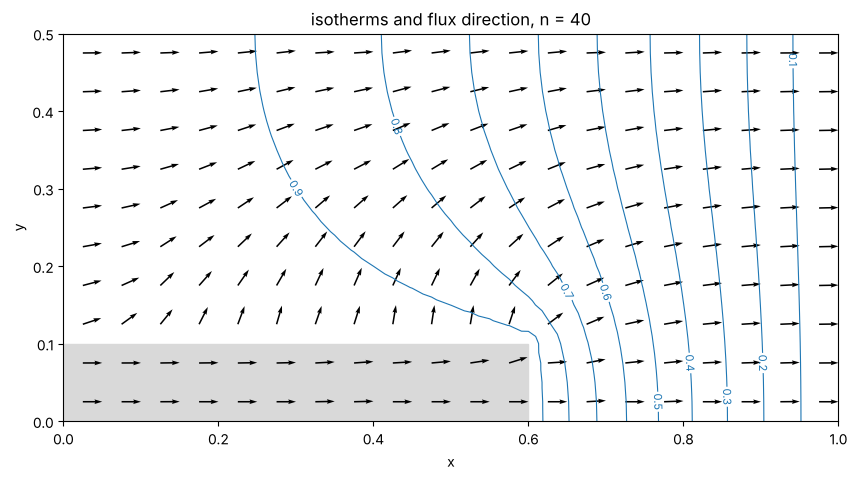

In [4]:
P, T, k = make_mesh(n_plot); th, Q1, q1 = solve_p1(P, T, k); r = solve_rt(P, T, k)
tri = mtri.Triangulation(P[:, 0], P[:, 1], T); finder = tri.get_trifinder()
fig, ax = plt.subplots(figsize=(10, 5.4))
ax.add_patch(plt.Rectangle((0, 0), xb, yb, color='0.85'))
cs = ax.tricontour(tri, th, levels=np.arange(0.1, 1.0, 0.1), colors='C0', linewidths=0.8)
ax.clabel(cs, fmt='%.1f', fontsize=8)
pts = np.array([(x, y) for x in np.linspace(0.025, 0.975, 20) for y in np.linspace(0.025, H - 0.025, 10)])
Qv = np.array([rt_value(P, T, r, finder(*p), p) for p in pts])
Qv /= np.linalg.norm(Qv, axis=1)[:, None]
ax.quiver(pts[:, 0], pts[:, 1], Qv[:, 0], Qv[:, 1], scale=40, width=0.002)
ax.set_aspect('equal'); ax.set_xlim(0, 1); ax.set_ylim(0, H); ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title(f'isotherms and flux direction, n = {n_plot}'); plt.show()

## What the normal continuity buys
The normal flux $q_y$ across the top face $y = y_b$ of the insert: linear elements give one value in the insert
and another in the insulation, Raviart–Thomas elements one value on both sides.

n = 20: heat through the top face, P1 0.2883 (insert side) / 0.4442 (insulation side), RT 0.4504
n = 40: heat through the top face, P1 0.3653 (insert side) / 0.4502 (insulation side), RT 0.4526
n = 80: heat through the top face, P1 0.4077 (insert side) / 0.4526 (insulation side), RT 0.4534


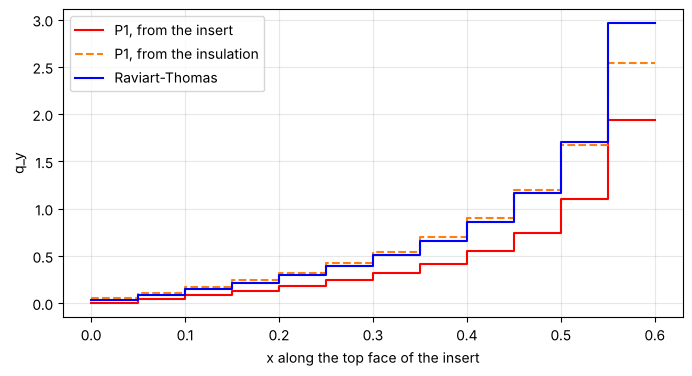

In [5]:
def face_flux(n):
    P, T, k = make_mesh(n); th, Q1, q1 = solve_p1(P, T, k); r = solve_rt(P, T, k)
    cen = P[T].mean(1); rows = []
    for e in np.where(np.isclose(r['mid'][:, 1], yb) & (r['mid'][:, 0] < xb))[0]:
        ts = [t for t in range(len(T)) if e in r['TE'][t]]
        below = [t for t in ts if cen[t, 1] < yb][0]; above = [t for t in ts if cen[t, 1] > yb][0]
        rows.append((r['mid'][e, 0], r['L'][e], q1[below][1], q1[above][1], np.sign(r['nrm'][e][1])*r['q'][e]/r['L'][e]))
    return np.array(sorted(rows))

rows = face_flux(20)
fig, ax = plt.subplots(figsize=(8, 4))
for col, lab, st in [(2, 'P1, from the insert', 'r-'), (3, 'P1, from the insulation', 'C1--'), (4, 'Raviart-Thomas', 'b-')]:
    ax.step(np.r_[rows[:, 0] - rows[:, 1]/2, xb], np.r_[rows[:, col], rows[-1, col]], st, where='post', label=lab)
ax.set_xlabel('x along the top face of the insert'); ax.set_ylabel('q_y'); ax.legend(); ax.grid(alpha=0.3); plt.show()
for n in [20, 40, 80]:
    rows = face_flux(n); tot = lambda c: (rows[:, 1]*rows[:, c]).sum()
    print(f"n = {n}: heat through the top face, P1 {tot(2):.4f} (insert side) / {tot(3):.4f} (insulation side), RT {tot(4):.4f}")

## Things to try
1. Lower the contrast, `k_b = 2`: the two $P_1$ fluxes on the face of the insert get closer. Why?
2. Let the insert cross the whole wall, `xb = 1`: the temperature is $1 - x$ everywhere and the problem is
   one-dimensional. What do the two bounds give?
3. Raise the contrast to `k_b = 1000`: how do the bounds and their gap change?
4. Check the balance of heat of the linear elements: compute the heat entering at $x = 0$ and leaving at $x = 1$
   from the element fluxes `q1`. Do they agree? And for the Raviart–Thomas flux (`r['Q']`, `r['Qout']`)?